# HealthRisk AI — Exploratory Data Analysis

Diabetes 130-US Hospitals (1999–2008). This notebook **calls the same pipeline code** used in production
(`ml/data_ingestion.py`, `ml/validation.py`, `ml/eda.py`), so every number here matches the dashboard.
All statistics are computed at run time — nothing is hard-coded.

Run from the repository root: `jupyter nbconvert --to notebook --execute notebooks/exploratory_analysis.ipynb --inplace`

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "ml").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import ml
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from ml.data_ingestion import load_raw, build_cohort
from ml.validation import quality_checks
from ml.eda import compute_eda, make_figures
from ml.feature_engineering import engineer_frame
pd.set_option("display.max_columns", 60)

## 1. Load and validate the raw dataset

In [2]:
raw = load_raw()
print(raw.shape)
# identifiers dropped from the preview (they are only used as grouping keys)
raw.drop(columns=["encounter_id", "patient_nbr"]).head(3)

(101766, 50)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


In [3]:
q = quality_checks(raw)
print({k: q[k] for k in ['rows','unique_encounters','unique_patients','duplicate_encounter_ids','patients_with_multiple_encounters','max_encounters_per_patient','encounters_from_repeat_patients_pct']})
pd.Series(q['missing_pct'], name='missing %').to_frame()

{'rows': 101766, 'unique_encounters': 101766, 'unique_patients': 71518, 'duplicate_encounter_ids': 0, 'patients_with_multiple_encounters': 16773, 'max_encounters_per_patient': 40, 'encounters_from_repeat_patients_pct': 46.21}


,missing %
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


**Observations (data-driven):** `weight` is almost entirely missing and is excluded; `medical_specialty` and
`payer_code` are heavily missing. Many patients have repeat encounters, which is why every split in this project
is grouped by `patient_nbr`.

## 2. Target definition and cohort

In [4]:
cohort, log = build_cohort(raw)
display(pd.Series(log, name='count').to_frame())
display(pd.crosstab(cohort['readmitted'], cohort['readmitted_30d'], margins=True))
print(f"Positive class (readmitted <30 days): {cohort['readmitted_30d'].mean():.2%}")

,count
raw_rows,101766
removed_duplicate_encounters,0
removed_expired_or_hospice,2423
removed_invalid_gender,3
cohort_rows,99340
cohort_patients,69987


readmitted_30d,0,1,All
readmitted,,,
<30,0,11314,11314
>30,35502,0,35502
NO,52524,0,52524
All,88026,11314,99340


Positive class (readmitted <30 days): 11.39%


Binary target: **1 = `<30`**, **0 = `>30` or `NO`**. Encounters ending in death or hospice are removed because those
patients are not at risk of readmission.

## 3. Univariate, bivariate and multivariate analysis

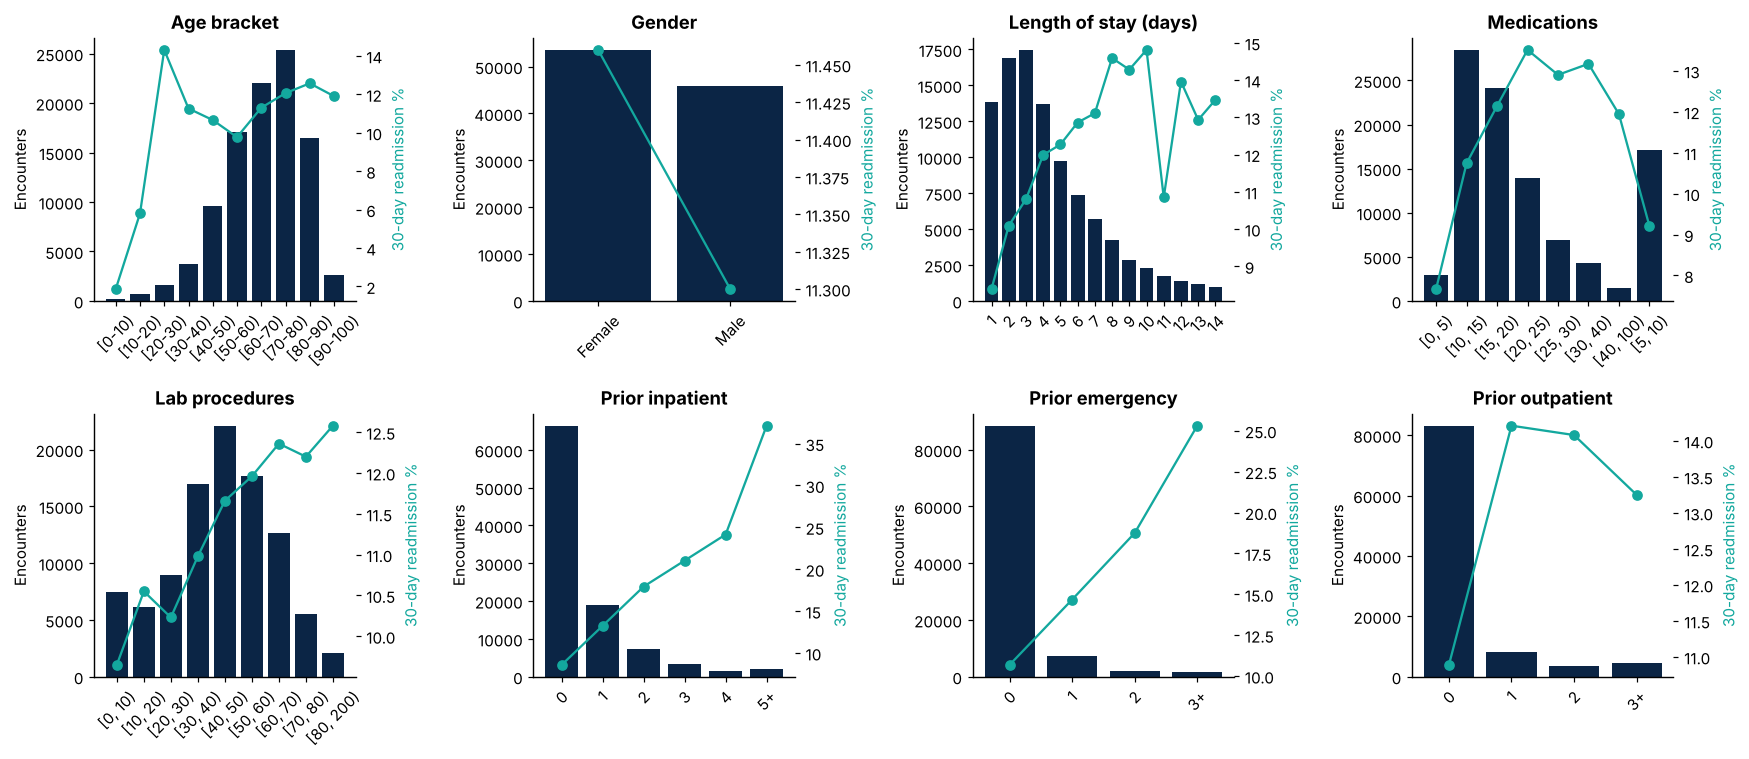

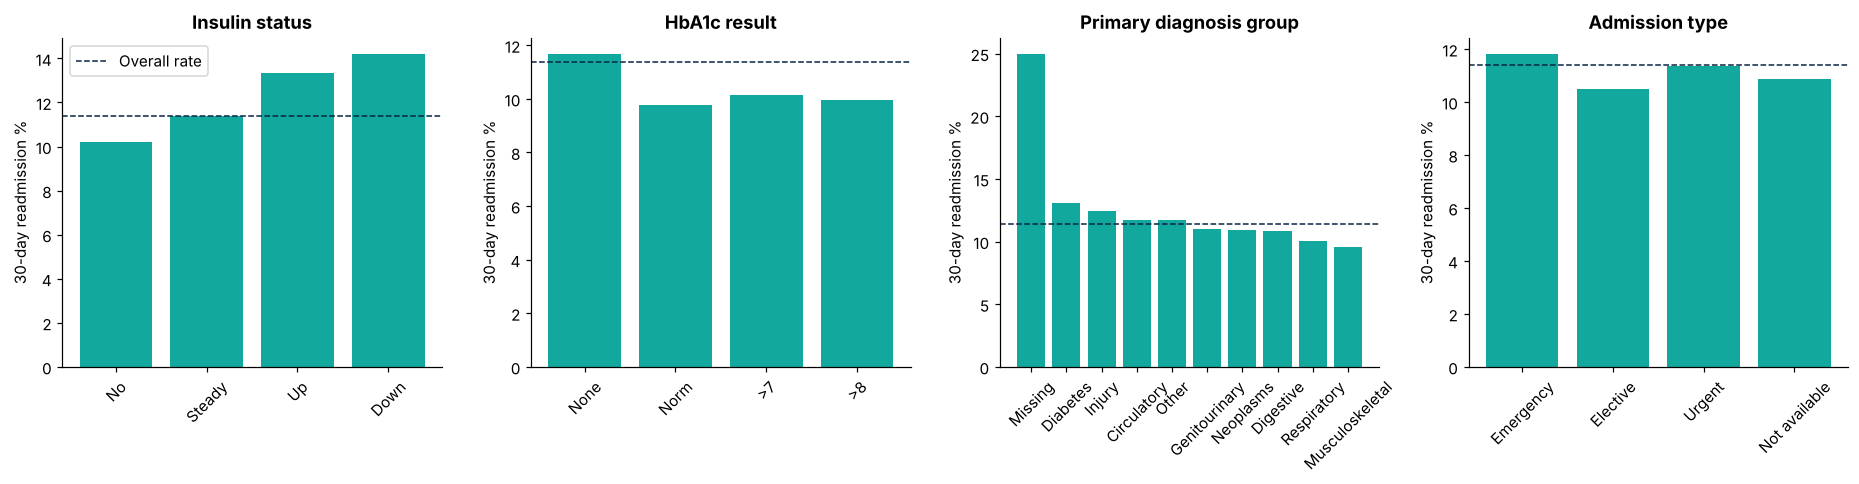

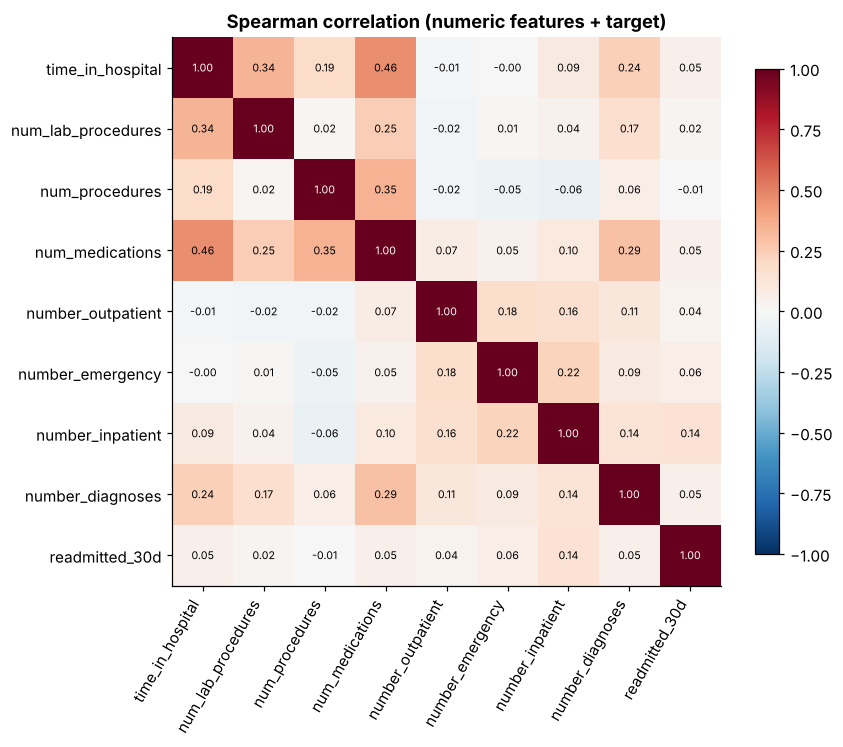

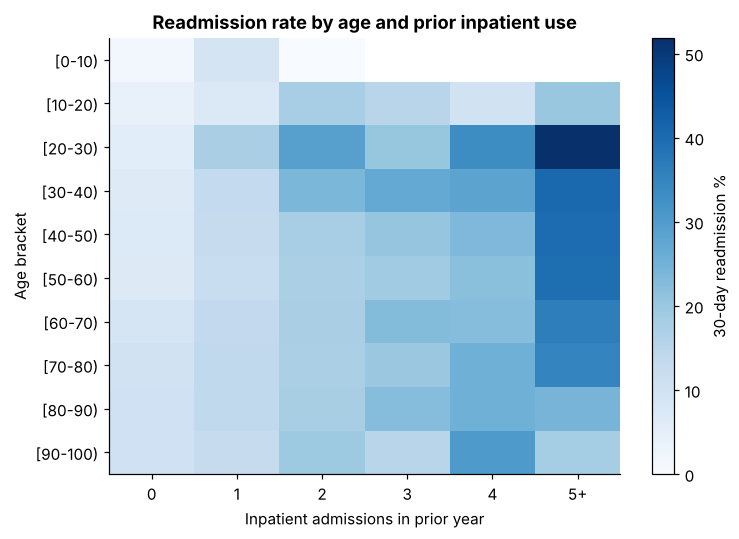

In [5]:
summary = compute_eda(cohort)
figs = make_figures(cohort, summary)
for f in figs:
    display(Image(filename=str(ROOT / f)))

In [6]:
pd.DataFrame(summary['descriptive_stats']).T

,mean,median,std,min,max,q1,q3,missing_pct
time_in_hospital,4.379,4.0,2.968,1.0,14.0,2.0,6.0,0.0
num_lab_procedures,42.907,44.0,19.610,1.0,132.0,31.0,57.0,0.0
num_procedures,1.334,1.0,1.703,0.0,6.0,0.0,2.0,0.0
num_medications,15.979,15.0,8.095,1.0,81.0,10.0,20.0,0.0
number_outpatient,0.369,0.0,1.265,0.0,42.0,0.0,0.0,0.0
number_emergency,0.198,0.0,0.938,0.0,76.0,0.0,0.0,0.0
number_inpatient,0.631,0.0,1.260,0.0,21.0,0.0,1.0,0.0
number_diagnoses,7.402,8.0,1.941,1.0,16.0,6.0,9.0,0.0


In [7]:
pd.DataFrame(summary['bivariate']['medical_specialty'])

,group,count,rate
0,Missing,48614,0.1183
1,InternalMedicine,14237,0.1153
2,Emergency/Trauma,7419,0.1139
3,Family/GeneralPractice,7252,0.1212
4,Cardiology,5278,0.0803
5,Surgery-General,3059,0.1118
6,Nephrology,1539,0.1611
7,Orthopedics,1392,0.1085
8,Orthopedics-Reconstructive,1230,0.0748
9,Radiologist,1121,0.0910


## 4. Statistical tests (effect sizes)

In [8]:
display(pd.DataFrame(summary['statistical_tests']['categorical_chi_square']))
display(pd.DataFrame(summary['statistical_tests']['numeric_mann_whitney']))
print(summary['statistical_tests']['caveat'])

,feature,chi2,dof,p_value,cramers_v
0,discharge_disposition,1314.31,19,3.015765e-267,0.1150
1,specialty,372.96,72,3.631641e-42,0.0613
2,insulin,199.22,3,6.221589e-43,0.0448
3,age,133.62,9,2.128621e-24,0.0367
4,diag_1_group,85.47,9,1.316100e-14,0.0293
5,metformin,69.91,3,4.466877e-15,0.0265
6,diabetesMed,66.75,1,3.076948e-16,0.0260
7,A1Cresult,42.58,3,3.026712e-09,0.0207
8,change,34.15,1,5.100859e-09,0.0186
9,admission_type,29.99,5,1.479227e-05,0.0174


,feature,mean_readmitted,mean_not_readmitted,median_readmitted,median_not_readmitted,rank_biserial,p_value
0,time_in_hospital,4.768,4.329,4.0,4.0,0.0954,1.587928e-62
1,num_lab_procedures,44.222,42.738,45.0,44.0,0.0438,2.910622e-14
2,num_procedures,1.283,1.341,1.0,1.0,-0.0078,1.528420e-01
3,num_medications,16.909,15.860,16.0,15.0,0.0872,9.394582e-52
4,number_outpatient,0.437,0.361,0.0,0.0,0.0407,7.719281e-28
5,number_emergency,0.358,0.178,0.0,0.0,0.0640,1.244690e-91
6,number_inpatient,1.223,0.555,0.0,0.0,0.2145,0.000000e+00
7,number_diagnoses,7.692,7.364,9.0,8.0,0.0880,2.632621e-59


Encounters from the same patient are not independent, so p-values are optimistic; use effect sizes (Cramér's V, rank-biserial) for ranking.


## 5. Engineered features

In [9]:
X = engineer_frame(cohort)
fe = X[['total_prior_visits','meds_per_day','n_diabetes_meds','n_med_dose_changes','los_category','diag_1_group']].copy()
fe['readmitted_30d'] = cohort['readmitted_30d'].values
display(fe.groupby('diag_1_group')['readmitted_30d'].agg(['size','mean']).sort_values('mean', ascending=False))
display(fe.groupby('los_category')['readmitted_30d'].agg(['size','mean']))

,size,mean
diag_1_group,,
Missing,20,0.250000
Diabetes,8661,0.131047
Injury,6851,0.124069
Circulatory,29680,0.116880
Other,17793,0.116844
Genitourinary,5002,0.110356
Neoplasms,3131,0.108911
Digestive,9333,0.108218
Respiratory,13934,0.100617


,size,mean
los_category,,
1-2 days,30713,0.093250
3-6 days,48220,0.117503
7+ days,20407,0.136424


## 6. Findings (generated from the computed summary)

In [10]:
display(Markdown("\n".join(f"- {f}" for f in summary['findings'])))

- 11,314 of 99,340 cohort encounters (11.4%) were readmitted within 30 days - a class imbalance of about 7.8:1, so accuracy alone would be misleading.
- The readmission rate rises from 8.6% for patients with no inpatient stay in the prior year to 37.1% for those with 5+ prior stays.
- Prior emergency visits show a similar gradient: 10.7% (none) vs 25.3% (3+ visits).
- Among age brackets with at least 1,000 encounters, the rate ranges from 9.8% ([50-60)) to 14.3% ([20-30)).
- Readmission is 8.4% after a 1-day stay and 13.5% after a 14-day stay.
- Discharge destination matters: 'Rehab facility' has a 27.7% rate vs 'Home' at 9.3% (groups with ≥1,000 encounters).
- HbA1c was not measured in 83% of encounters; readmission rate is 11.7% when untested vs 9.9% when >8%.
- Encounters where insulin was adjusted (Up 13.3%, Down 14.2%) show higher rates than no insulin (10.2%).
- By effect size, the categorical variable most associated with readmission is 'discharge_disposition' (Cramér's V = 0.115); all associations are weak individually, which foreshadows modest discrimination for any model on this dataset.